In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [61]:
edges = np.load("processed/edges.npz")
recipes = pd.read_csv("processed/recipes.csv")
ingr_map = pd.read_csv("processed/ingredient_map.csv")
ingr = pd.read_csv("processed/ingredients.csv")

In [62]:
edges['train'].T

array([[   0,   91],
       [   1,   46],
       [   2,   95],
       ...,
       [6633,  644],
       [2604,  689],
       [7519,  283]], shape=(51925, 2))

In [63]:
ingr_map

,raw,canonical,count,kept
0,salt,salt,3964,True
1,sugar,sugar,3569,True
2,flour,flour,2592,True
3,eggs,egg,2330,True
4,butter,butter,2258,True
...,...,...,...,...
4174,pasteurized cheese,pasteurized cheese,1,False
4175,whole kernel golden corn,whole kernel golden corn,1,False
4176,crisply cooked bacon,crisply cooked bacon,1,False
4177,game hens,game hen,1,False


In [64]:
recipes

,recipe_id,row_id,title,link,source,ings,n_ings,heldout
0,0,0,No-Bake Nut Cookies,www.cookbooks.com/Recipe-Details.aspx?id=44874,Gathered,brown sugar|butter|milk|nut|vanilla,5,False
1,1,1,Jewell Ball'S Chicken,www.cookbooks.com/Recipe-Details.aspx?id=699419,Gathered,beef|chicken breast|cream of mushroom soup|sou...,4,False
2,2,2,Creamy Corn,www.cookbooks.com/Recipe-Details.aspx?id=10570,Gathered,butter|corn|cream cheese|garlic powder|pepper|...,6,False
3,3,3,Chicken Funny,www.cookbooks.com/Recipe-Details.aspx?id=897570,Gathered,cheese|chicken|cream of mushroom soup,3,False
4,4,4,Reeses Cups(Candy),www.cookbooks.com/Recipe-Details.aspx?id=659239,Gathered,butter|chocolate chip|graham cracker crumb|pea...,5,False
...,...,...,...,...,...,...,...,...
9824,9824,9995,Pink Fruit Salad,www.cookbooks.com/Recipe-Details.aspx?id=183170,Gathered,cherry pie filling|condensed milk|lemon juice|...,5,False
9825,9825,9996,Peppered Steak,www.cookbooks.com/Recipe-Details.aspx?id=462037,Gathered,bell pepper|cooking oil|onion|salt|soy sauce|t...,6,False
9826,9826,9997,Chicken Casserole,www.cookbooks.com/Recipe-Details.aspx?id=292083,Gathered,celery|cheddar cheese|chicken broth|cream of m...,10,False
9827,9827,9998,Sweet Potatoes Casserole,www.cookbooks.com/Recipe-Details.aspx?id=56276,Gathered,egg|milk|sugar|vanilla flavoring|yam,5,False


In [65]:
ingr

,ingredient_id,name,recipe_count
0,0,accent,29
1,1,active dry yeast,19
2,2,all-purpose,108
3,3,all-purpose flour,10
4,4,allspice,94
...,...,...,...
820,820,yellow onion,12
821,821,yellow squash,18
822,822,yogurt,18
823,823,your choice,6


In [66]:
node2vec = np.load("node2vec/embeddings.npz")

In [67]:
embs = node2vec['recipe_embeddings']

salad1_index = 9824
salad2_index = 9828
chicken1_index = 3
chicken2_index = 9826

salad1 = np.array(embs[salad1_index])
salad2 = np.array(embs[salad2_index])
chicken1 = np.array(embs[chicken1_index])
chicken2 = np.array(embs[chicken2_index])

print("salad Euclidean distance:", np.linalg.norm(salad1 - salad2))
print("chicken Euclidean distance:", np.linalg.norm(chicken1 - chicken2))
print("chicken - salad Euclidean distance:", np.linalg.norm(chicken1 - salad1))

salad Euclidean distance: 1.405132
chicken Euclidean distance: 1.1329291
chicken - salad Euclidean distance: 1.586498


In [75]:
from sklearn.manifold import TSNE


def plot_embedding_by_ingredient(
    ingredient,
    embeddings=None,
    recipes_df=None,
    title=None,
    figsize=(10, 8),
    alpha=0.6,
    point_size=12,
):
    """Plot recipe embeddings, coloring recipes by ingredient membership."""
    if embeddings is None:
        embeddings = node2vec["recipe_embeddings"]
    if recipes_df is None:
        recipes_df = recipes

    if len(embeddings) != len(recipes_df):
        raise ValueError(
            "The number of embeddings must match the number of recipe rows."
        )
    if "ings" not in recipes_df:
        raise ValueError("recipes_df must contain an 'ings' column.")

    ingredient = ingredient.strip().lower()
    if not ingredient:
        raise ValueError("ingredient must not be empty.")

    has_ingredient = recipes_df["ings"].fillna("").map(
        lambda value: ingredient in {
            item.strip().lower() for item in value.split("|") if item.strip()
        }
    ).to_numpy()

    if len(embeddings) < 3:
        raise ValueError("t-SNE requires at least three embeddings.")
    coordinates = TSNE(
        n_components=2,
        perplexity=min(30, len(embeddings) - 1),
        init="pca",
        learning_rate="auto",
        random_state=0,
    ).fit_transform(embeddings)

    figure, axis = plt.subplots(figsize=figsize)
    axis.scatter(
        coordinates[~has_ingredient, 0],
        coordinates[~has_ingredient, 1],
        c="lightgray",
        alpha=alpha,
        s=point_size,
        label="Does not contain ingredient",
    )
    axis.scatter(
        coordinates[has_ingredient, 0],
        coordinates[has_ingredient, 1],
        c="tab:red",
        alpha=alpha,
        s=point_size,
        label=f"Contains {ingredient}",
    )
    axis.set_title(title or f"Recipe embeddings colored by '{ingredient}'")
    axis.set_xlabel("t-SNE dimension 1")
    axis.set_ylabel("t-SNE dimension 2")
    axis.legend()
    figure.tight_layout()
    plt.show()

    print(f"Recipes containing {ingredient!r}: {has_ingredient.sum():,}")
    print(f"Other recipes: {(~has_ingredient).sum():,}")

    return figure, axis

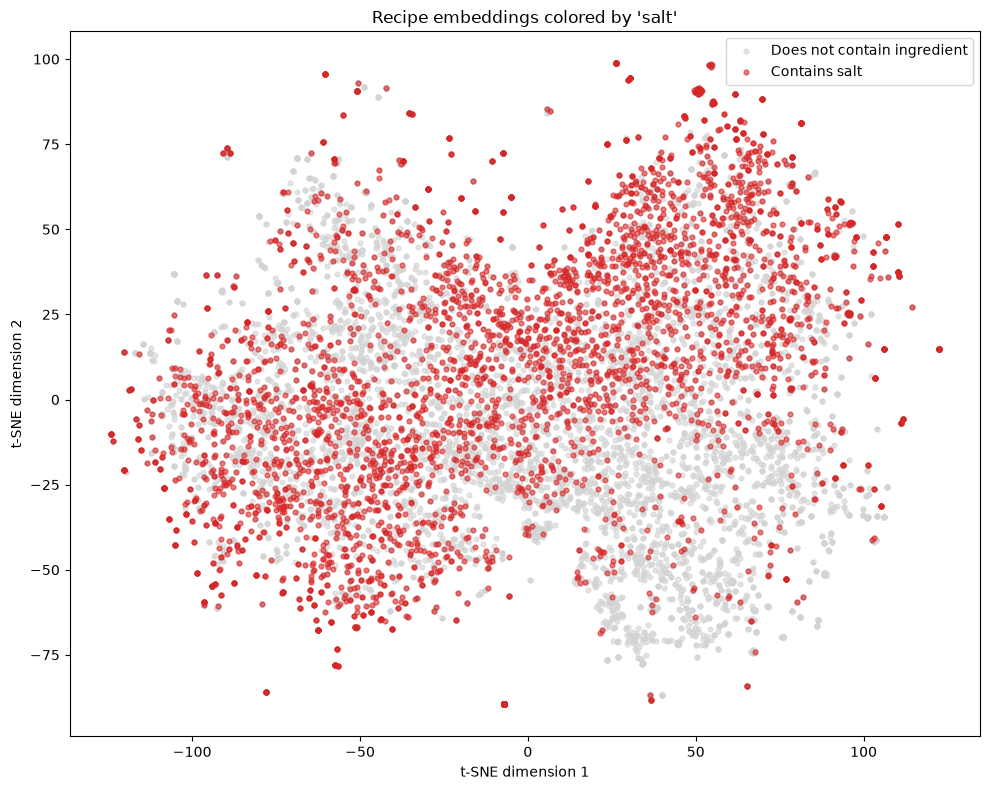

Recipes containing 'salt': 3,917
Other recipes: 5,912


(<Figure size 1000x800 with 1 Axes>,
 <Axes: title={'center': "Recipe embeddings colored by 'salt'"}, xlabel='t-SNE dimension 1', ylabel='t-SNE dimension 2'>)

In [84]:
shared_ingredient = 'salt'
plot_embedding_by_ingredient(shared_ingredient)

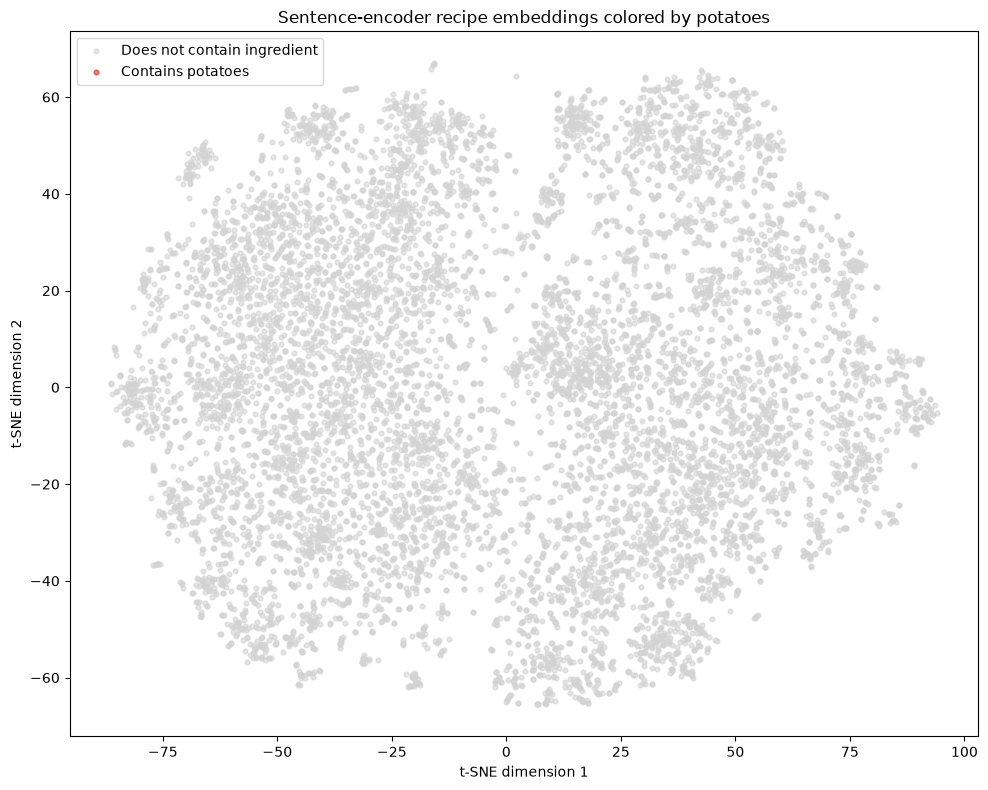

Recipes containing 'potatoes': 0
Other recipes: 9,829


(<Figure size 1000x800 with 1 Axes>,
 <Axes: title={'center': 'Sentence-encoder recipe embeddings colored by potatoes'}, xlabel='t-SNE dimension 1', ylabel='t-SNE dimension 2'>)

In [82]:
recipe_sentence_embeddings = np.load("processed/recipe_x_full.npy")

plot_embedding_by_ingredient(
    shared_ingredient,
    embeddings=recipe_sentence_embeddings,
    title=f"Sentence-encoder recipe embeddings colored by {shared_ingredient}"
)

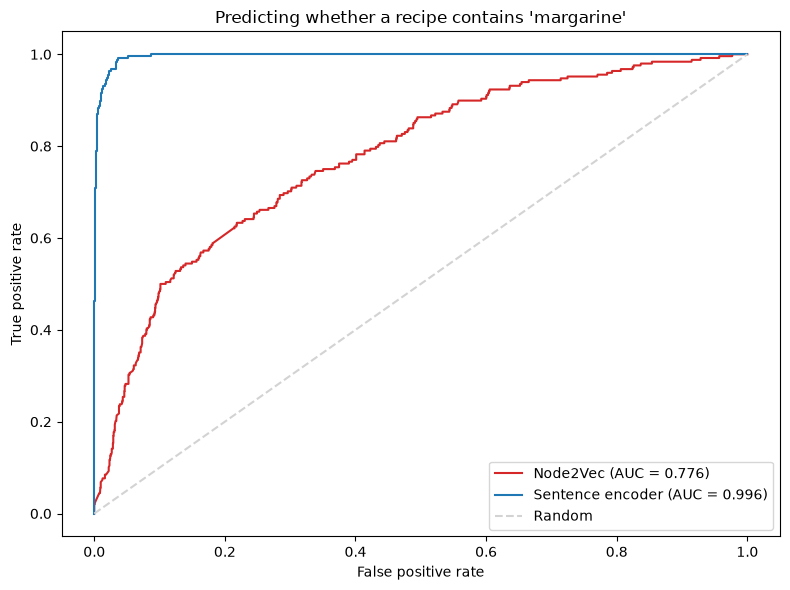

Ingredient: 'margarine'
Positive recipes: 1,238
Negative recipes: 8,591
Node2Vec held-out ROC AUC: 0.776
Sentence encoder held-out ROC AUC: 0.996


({'Node2Vec': {'classifier': LogisticRegression(max_iter=1000, random_state=0),
   'auc': 0.7759268560591837},
  'Sentence encoder': {'classifier': LogisticRegression(max_iter=1000, random_state=0),
   'auc': 0.9964864433512337}},
 <Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': "Predicting whether a recipe contains 'margarine'"}, xlabel='False positive rate', ylabel='True positive rate'>)

In [88]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split


def plot_ingredient_auc(
    ingredient,
    embeddings_by_name,
    recipes_df=None,
    test_size=0.2,
    random_state=0,
    title=None,
    figsize=(8, 6),
):
    """Plot held-out ROC curves for multiple recipe embedding spaces."""
    if recipes_df is None:
        recipes_df = recipes

    if not embeddings_by_name:
        raise ValueError("embeddings_by_name must contain at least one embedding set.")
    if "ings" not in recipes_df:
        raise ValueError("recipes_df must contain an 'ings' column.")

    ingredient = ingredient.strip().lower()
    if not ingredient:
        raise ValueError("ingredient must not be empty.")

    labels = recipes_df["ings"].fillna("").map(
        lambda value: ingredient in {
            item.strip().lower() for item in value.split("|") if item.strip()
        }
    ).to_numpy(dtype=np.int64)

    if labels.sum() == 0 or labels.sum() == len(labels):
        raise ValueError(
            f"'{ingredient}' must occur in both positive and negative recipe classes."
        )

    indices = np.arange(len(labels))
    train_indices, test_indices = train_test_split(
        indices,
        test_size=test_size,
        random_state=random_state,
        stratify=labels,
    )

    figure, axis = plt.subplots(figsize=figsize)
    results = {}
    colors = ["tab:red", "tab:blue", "tab:green", "tab:orange"]

    for (name, embedding_values), color in zip(embeddings_by_name.items(), colors):
        embeddings = np.asarray(embedding_values)
        if len(embeddings) != len(recipes_df):
            raise ValueError(
                f"'{name}' embeddings must match the number of recipe rows."
            )

        classifier = LogisticRegression(max_iter=1000, random_state=random_state)
        classifier.fit(embeddings[train_indices], labels[train_indices])
        probabilities = classifier.predict_proba(embeddings[test_indices])[:, 1]

        false_positive_rate, true_positive_rate, _ = roc_curve(
            labels[test_indices], probabilities
        )
        auc = roc_auc_score(labels[test_indices], probabilities)
        axis.plot(
            false_positive_rate,
            true_positive_rate,
            color=color,
            label=f"{name} (AUC = {auc:.3f})",
        )
        results[name] = {"classifier": classifier, "auc": auc}

    axis.plot([0, 1], [0, 1], linestyle="--", color="lightgray", label="Random")
    axis.set_title(title or f"Predicting whether a recipe contains '{ingredient}'")
    axis.set_xlabel("False positive rate")
    axis.set_ylabel("True positive rate")
    axis.legend(loc="lower right")
    figure.tight_layout()
    plt.show()

    print(f"Ingredient: {ingredient!r}")
    print(f"Positive recipes: {labels.sum():,}")
    print(f"Negative recipes: {(labels == 0).sum():,}")
    for name, result in results.items():
        print(f"{name} held-out ROC AUC: {result['auc']:.3f}")

    return results, figure, axis


plot_ingredient_auc(
    'margarine',
    embeddings_by_name={
        "Node2Vec": node2vec["recipe_embeddings"],
        "Sentence encoder": recipe_sentence_embeddings,
    }
)